# BigMart Sales: Exploratory Data Analysis
What drives `Item_Outlet_Sales`? Each section ends with the decision it led to in `src/data.py` or `src/features.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from src import config, data, features
sns.set_theme(style="whitegrid")
train, test = data.load_raw()
print(train.shape, test.shape)
train.head()

(8523, 12) (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 1. Missing values and data problems

In [2]:
pd.DataFrame({"train_missing_%": train.isna().mean()*100, "test_missing_%": test.isna().mean().reindex(train.columns)*100}).round(1)

,train_missing_%,test_missing_%
Item_Identifier,0.0,0.0
Item_Weight,17.2,17.2
Item_Fat_Content,0.0,0.0
Item_Visibility,0.0,0.0
Item_Type,0.0,0.0
Item_MRP,0.0,0.0
Outlet_Identifier,0.0,0.0
Outlet_Establishment_Year,0.0,0.0
Outlet_Size,28.3,28.3
Outlet_Location_Type,0.0,0.0


In [3]:
print(train["Item_Fat_Content"].value_counts(), "\n")
print("rows with Item_Visibility == 0:", (train["Item_Visibility"] == 0).sum())
print("Outlet_Size missing share by outlet:")
print(train.groupby("Outlet_Identifier")["Outlet_Size"].apply(lambda s: s.isna().mean()))

Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64 

rows with Item_Visibility == 0: 526
Outlet_Size missing share by outlet:
Outlet_Identifier
OUT010    1.0
OUT013    0.0
OUT017    1.0
OUT018    0.0
OUT019    0.0
OUT027    0.0
OUT035    0.0
OUT045    1.0
OUT046    0.0
OUT049    0.0
Name: Outlet_Size, dtype: float64


**Decisions:** merge the 5 fat-content spellings into 2; fill `Item_Weight` from the same item in other rows; the three outlets with no size at all (OUT010, OUT017, OUT045) get the most common size of their outlet type; treat zero visibility as missing.

## 2. The target

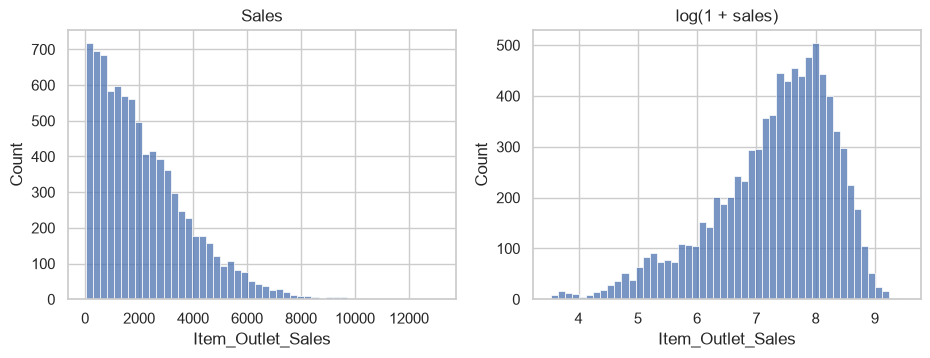

skew: 1.18


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(train[config.TARGET], bins=50, ax=ax[0]); ax[0].set_title("Sales")
sns.histplot(np.log1p(train[config.TARGET]), bins=50, ax=ax[1]); ax[1].set_title("log(1 + sales)")
plt.show()
print("skew:", train[config.TARGET].skew().round(2))

Sales are right-skewed. Log-transforming the target looks natural, but it made RMSE worse in cross-validation (1107 vs 1081 for LightGBM), because RMSE is measured on the original scale. So we model raw sales.

## 3. Price (Item_MRP) is the main driver

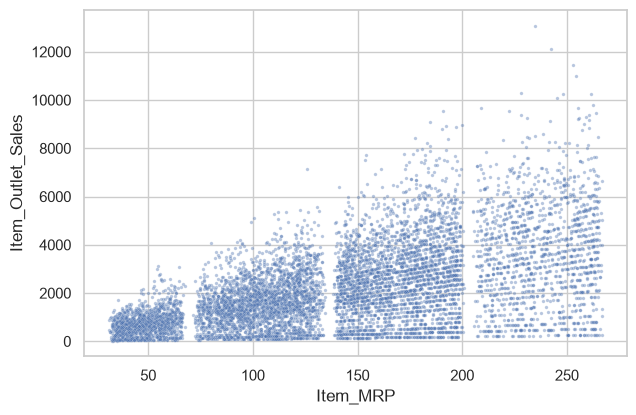

correlation with sales:
Item_Weight                  0.014
Item_Visibility             -0.129
Item_MRP                     0.568
Outlet_Establishment_Year   -0.049
Name: Item_Outlet_Sales, dtype: float64


In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=train, x="Item_MRP", y=config.TARGET, s=6, alpha=0.4, ax=ax)
plt.show()
print("correlation with sales:"); print(train.select_dtypes("number").corr()[config.TARGET].drop(config.TARGET).round(3))

Sales rise linearly with MRP, and the spread grows with price (a fan shape). Four price bands are visible.

## 4. The outlet changes the slope of that line

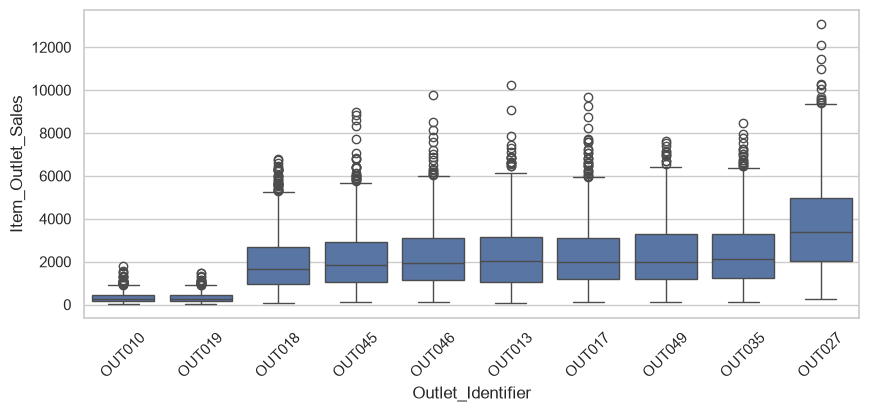

,,,,count,mean
Outlet_Identifier,Outlet_Type,Outlet_Size,Outlet_Location_Type,,
OUT010,Grocery Store,NaN,Tier 3,555,339.0
OUT013,Supermarket Type1,High,Tier 3,932,2299.0
OUT017,Supermarket Type1,NaN,Tier 2,926,2341.0
OUT018,Supermarket Type2,Medium,Tier 3,928,1995.0
OUT019,Grocery Store,Small,Tier 1,528,340.0
OUT027,Supermarket Type3,Medium,Tier 3,935,3694.0
OUT035,Supermarket Type1,Small,Tier 2,930,2439.0
OUT045,Supermarket Type1,NaN,Tier 2,929,2192.0
OUT046,Supermarket Type1,Small,Tier 1,930,2278.0


In [6]:
order = train.groupby("Outlet_Identifier")[config.TARGET].mean().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=train, x="Outlet_Identifier", y=config.TARGET, order=order, ax=ax); plt.xticks(rotation=45)
plt.show()
train.groupby(["Outlet_Identifier", "Outlet_Type", "Outlet_Size", "Outlet_Location_Type"], dropna=False)[config.TARGET].agg(["count", "mean"]).round(0)

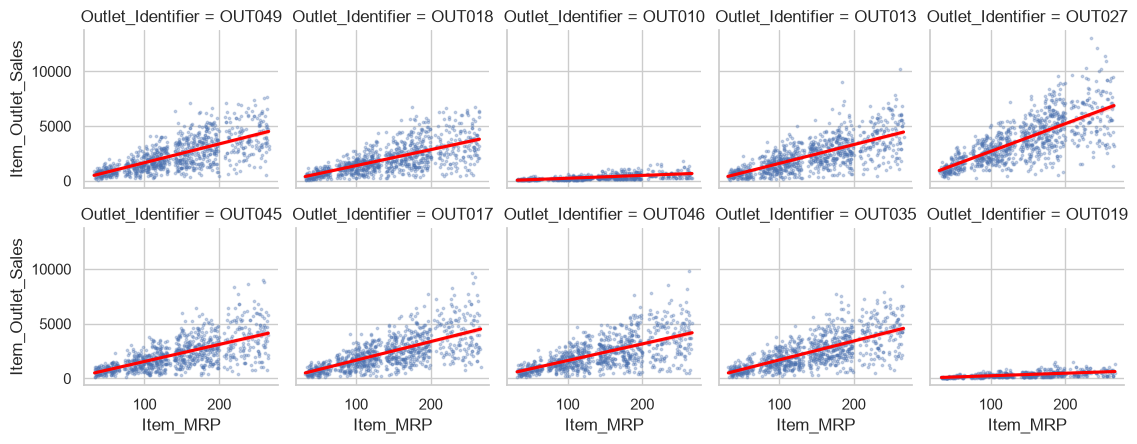

In [7]:
g = sns.FacetGrid(train, col="Outlet_Identifier", col_wrap=5, height=2.3, sharey=True)
g.map_dataframe(sns.regplot, x="Item_MRP", y=config.TARGET, scatter_kws=dict(s=3, alpha=0.3), line_kws=dict(color="red"))
plt.show()

**This is the key finding.** Within each outlet, sales are close to a straight line in MRP, but each outlet has its own slope. The two grocery stores (OUT010, OUT019) sell far less; OUT027 (Supermarket Type3) sells the most. A separate line per outlet beats gradient-boosted trees in cross-validation (RMSE 1071 vs 1080).

## 5. Other product features carry very little signal

{'Others': 1926.0, 'Baking Goods': 1953.0, 'Soft Drinks': 2007.0, 'Health and Hygiene': 2010.0, 'Breakfast': 2112.0, 'Frozen Foods': 2133.0, 'Hard Drinks': 2139.0, 'Meat': 2159.0, 'Breads': 2204.0, 'Canned': 2225.0, 'Dairy': 2233.0, 'Household': 2259.0, 'Snack Foods': 2277.0, 'Fruits and Vegetables': 2289.0, 'Seafood': 2326.0, 'Starchy Foods': 2374.0} 

{'reg': 1962.0, 'LF': 2074.0, 'low fat': 2088.0, 'Low Fat': 2164.0, 'Regular': 2235.0} 

{'Small': 1912.0, 'High': 2299.0, 'Medium': 2682.0} 

{'Tier 1': 1877.0, 'Tier 3': 2280.0, 'Tier 2': 2324.0} 



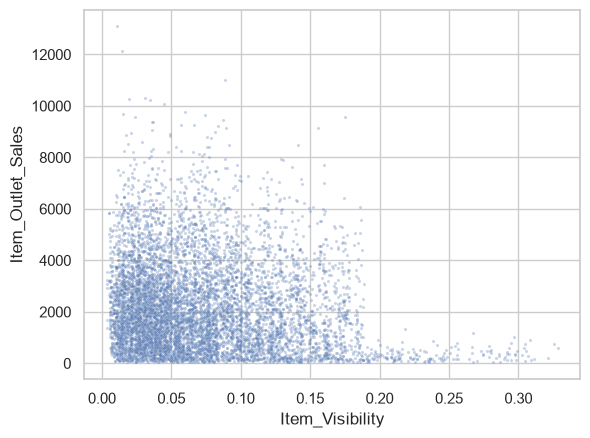

In [8]:
for col in ["Item_Type", "Item_Fat_Content", "Outlet_Size", "Outlet_Location_Type"]:
    print(train.groupby(col)[config.TARGET].mean().round(0).sort_values().to_dict(), "\n")
sns.scatterplot(data=train[train.Item_Visibility > 0], x="Item_Visibility", y=config.TARGET, s=5, alpha=0.3); plt.show()

Item type, fat content and visibility barely move the average once price and outlet are known. Dropping them or adding ten engineered variants changed CV RMSE by less than 3 points, which is inside the noise (fold-to-fold std is about 30).

## 6. Train and test look alike

In [9]:
for col in ["Outlet_Identifier", "Item_Type", "Outlet_Type"]:
    both = pd.concat([train[col].value_counts(normalize=True).rename("train"), test[col].value_counts(normalize=True).rename("test")], axis=1)
    print(both.round(3), "\n")
print("MRP mean  train/test:", train.Item_MRP.mean().round(1), test.Item_MRP.mean().round(1))
print("test items never seen in train:", (~test.Item_Identifier.isin(train.Item_Identifier)).sum())

                   train   test
Outlet_Identifier              
OUT027             0.110  0.110
OUT013             0.109  0.109
OUT049             0.109  0.109
OUT046             0.109  0.109
OUT035             0.109  0.109
OUT045             0.109  0.109
OUT018             0.109  0.109
OUT017             0.109  0.109
OUT010             0.065  0.065
OUT019             0.062  0.062 

                       train   test
Item_Type                          
Fruits and Vegetables  0.145  0.137
Snack Foods            0.141  0.139
Household              0.107  0.112
Frozen Foods           0.100  0.100
Dairy                  0.080  0.080
Canned                 0.076  0.077
Baking Goods           0.076  0.077
Health and Hygiene     0.061  0.059
Soft Drinks            0.052  0.049
Meat                   0.050  0.055
Breads                 0.029  0.029
Hard Drinks            0.025  0.026
Others                 0.020  0.020
Starchy Foods          0.017  0.021
Breakfast              0.013  0.013
Se

No distribution shift: test is a random sample from the same outlets and items, so cross-validation on train is a fair guide.

## Summary
1. Predict **raw** sales (not log).
2. The model is essentially **outlet x MRP**; everything else adds almost nothing.
3. About 1070 RMSE appears to be the noise floor with these columns.